# PART I

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, random_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_curve, auc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

## LOADING THE DATASET AND MAIN STATISTICS

In [2]:
df = pd.read_csv("dataset.csv")
print("Dataset shape:", df.shape)
print("\nBasic statistics:")
display(df.describe(include="all"))

Dataset shape: (766, 8)

Basic statistics:


,f1,f2,f3,f4,f5,f6,f7,target
count,766,766,766.000000,766,766,766,766,766.000000
unique,18,137,NaN,52,186,249,517,NaN
top,1,99,NaN,0,0,32,0.254,NaN
freq,134,17,NaN,226,372,13,6,NaN
mean,NaN,NaN,69.118799,NaN,NaN,NaN,NaN,0.349869
std,NaN,NaN,19.376901,NaN,NaN,NaN,NaN,0.477240
min,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,0.000000
25%,NaN,NaN,62.500000,NaN,NaN,NaN,NaN,0.000000
50%,NaN,NaN,72.000000,NaN,NaN,NaN,NaN,0.000000
75%,NaN,NaN,80.000000,NaN,NaN,NaN,NaN,1.000000


In [3]:
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].replace(['?', ' ?', '  ?'], np.nan)
        df[col] = pd.to_numeric(df[col], errors='coerce')

In [4]:
missing_before = df.isnull().sum().sum()
for col in df.columns:
    if df[col].isnull().any():
        median_val = df[col].median()
        df[col].fillna(median_val, inplace=True)

In [5]:
feature_cols = df.columns[:-1]
target_col = df.columns[-1]

In [6]:
zero_counts = {}
for col in feature_cols:
    zero_count = (df[col] == 0).sum()
    zero_counts[col] = zero_count
    if zero_count > 0:
        print(f"  {col}: {zero_count} zeros ({zero_count/len(df)*100:.2f}%)")
total_zeros = sum(zero_counts.values())
print(f"\nTotal zeros in features: {total_zeros}")

  f1: 111 zeros (14.49%)
  f2: 5 zeros (0.65%)
  f3: 35 zeros (4.57%)
  f4: 226 zeros (29.50%)
  f5: 372 zeros (48.56%)
  f6: 11 zeros (1.44%)

Total zeros in features: 760


In [7]:
df_cleaned = df.copy()

In [8]:
for col in feature_cols:
    if (df_cleaned[col] == 0).any():
        non_zero_median = df_cleaned[df_cleaned[col] != 0][col].median()
        zero_mask = df_cleaned[col] == 0
        df_cleaned.loc[zero_mask, col] = non_zero_median

In [9]:
for col in feature_cols:
    Q1 = df_cleaned[col].quantile(0.25)
    Q3 = df_cleaned[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_cleaned[col] = df_cleaned[col].clip(lower=lower_bound, upper=upper_bound)

In [10]:
duplicates = df_cleaned.duplicated().sum()
if duplicates > 0:
    df_cleaned = df_cleaned.drop_duplicates()

In [11]:
unique_targets = df_cleaned[target_col].unique()

In [12]:
if not np.array_equal(sorted(unique_targets), [0, 1]):
    if np.array_equal(sorted(unique_targets), [1, 2]):
        df_cleaned[target_col] = df_cleaned[target_col] - 1
    elif np.array_equal(sorted(unique_targets), [-1, 1]):
        df_cleaned[target_col] = (df_cleaned[target_col] + 1) / 2

In [13]:
class_counts = df_cleaned[target_col].value_counts()
class_ratio = max(class_counts) / min(class_counts)
for cls, count in class_counts.items():
    print(f"  Class {cls}: {count} samples ({count/len(df_cleaned)*100:.2f}%)")
print(f"  Imbalance ratio: {class_ratio:.2f}")

  Class 0: 498 samples (65.01%)
  Class 1: 268 samples (34.99%)
  Imbalance ratio: 1.86


In [14]:
print(df_cleaned.describe())

               f1          f2          f3          f4          f5          f6  \
count  766.000000  766.000000  766.000000  766.000000  766.000000  766.000000   
mean     4.399478  121.668407   72.379896   28.859661  124.583388   32.400000   
std      2.895062   30.386353   11.700536    7.453969    9.898552    6.674217   
min      1.000000   44.000000   40.000000   14.500000  109.625000   18.200000   
25%      2.000000  100.000000   64.000000   25.000000  120.500000   27.500000   
50%      4.000000  117.000000   72.000000   29.000000  125.000000   32.300000   
75%      6.000000  140.000000   80.000000   32.000000  127.750000   36.600000   
max     12.000000  199.000000  104.000000   42.500000  138.625000   50.250000   

               f7      target  
count  766.000000  766.000000  
mean     0.458919    0.349869  
std      0.285272    0.477240  
min      0.078000    0.000000  
25%      0.244000    0.000000  
50%      0.374000    0.000000  
75%      0.625500    1.000000  
max      1.197

In [15]:
df_cleaned.to_csv('dataset_cleaned.csv', index=False)

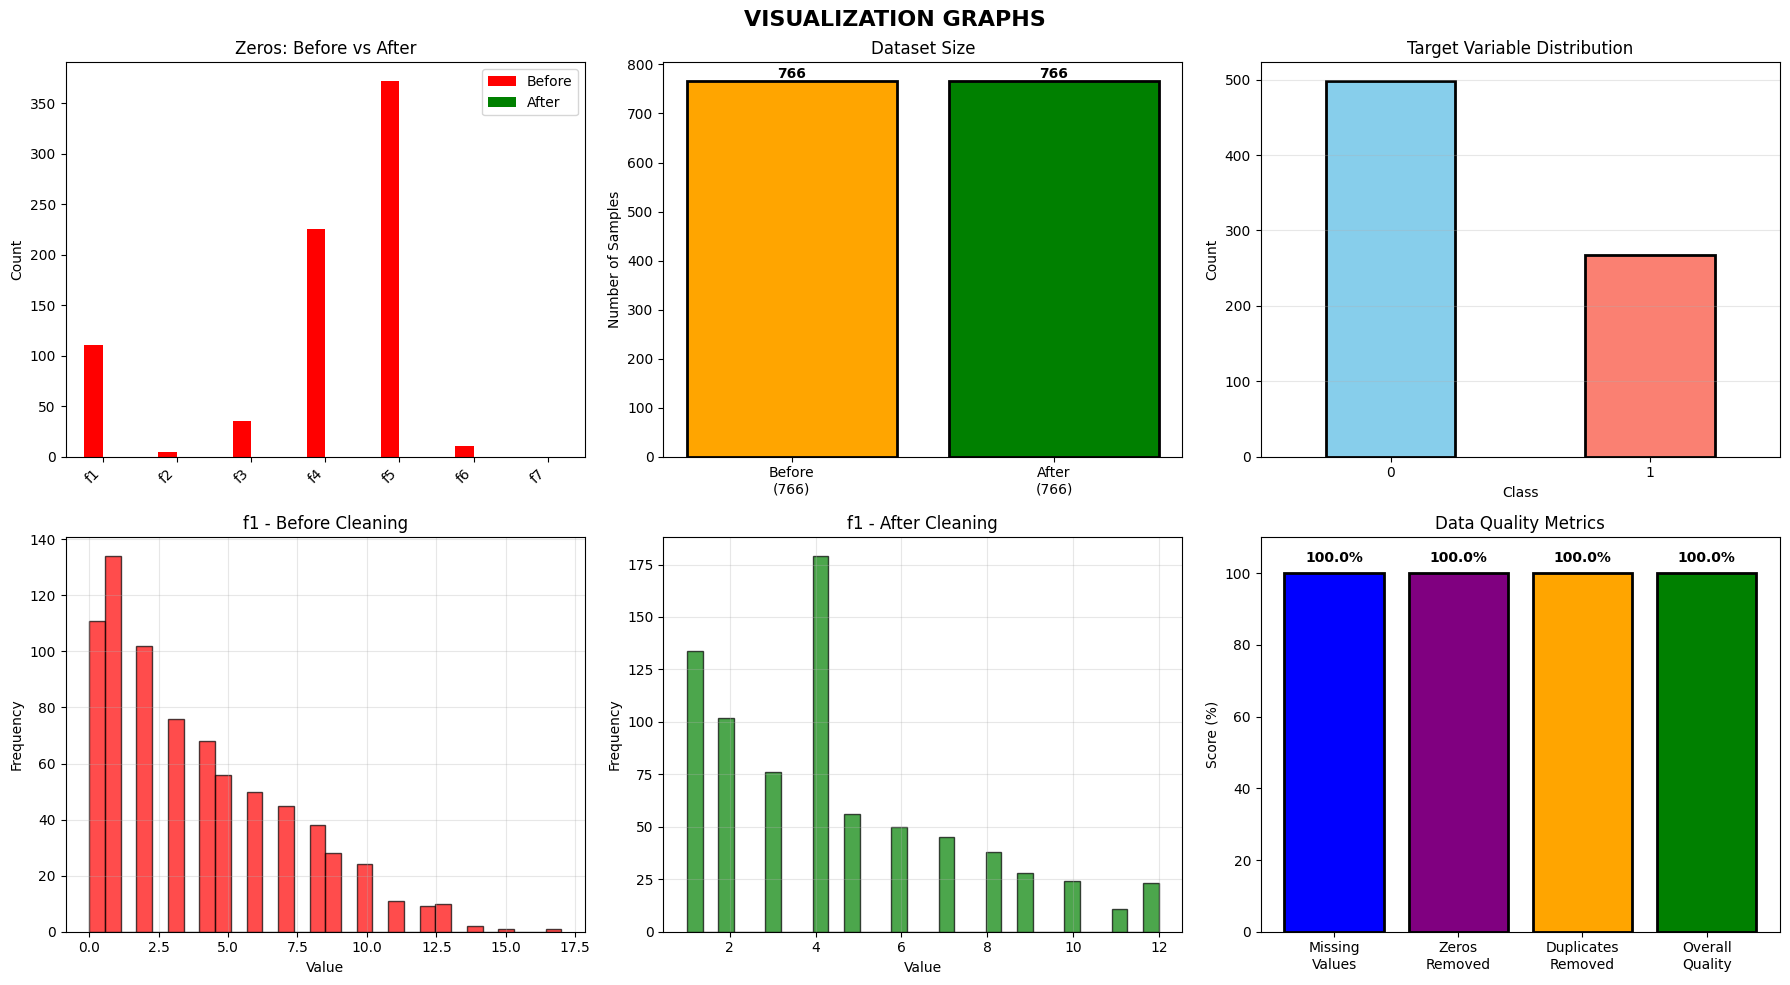

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('VISUALIZATION GRAPHS', fontsize=16, fontweight='bold')
ax1 = axes[0, 0]
zero_data = pd.DataFrame({'Before': [(df[col] == 0).sum() for col in feature_cols],'After': [(df_cleaned[col] == 0).sum() for col in feature_cols]}, index=feature_cols)
zero_data.plot(kind='bar', ax=ax1, color=['red', 'green'])
ax1.set_title('Zeros: Before vs After')
ax1.set_ylabel('Count')
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha='right')
ax1.legend()
ax2 = axes[0, 1]
sizes = [len(df), len(df_cleaned)]
labels = [f'Before\n({len(df)})', f'After\n({len(df_cleaned)})']
bars = ax2.bar(labels, sizes, color=['orange', 'green'], edgecolor='black', linewidth=2)
ax2.set_title('Dataset Size')
ax2.set_ylabel('Number of Samples')
for bar in bars:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height, f'{int(height)}',ha='center', va='bottom', fontweight='bold')
ax3 = axes[0, 2]
df_cleaned[target_col].value_counts().sort_index().plot(kind='bar', ax=ax3,color=['skyblue', 'salmon'],edgecolor='black', linewidth=2)
ax3.set_title('Target Variable Distribution')
ax3.set_xlabel('Class')
ax3.set_ylabel('Count')
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=0)
ax3.grid(True, alpha=0.3, axis='y')
ax4 = axes[1, 0]
df[feature_cols[0]].hist(bins=30, ax=ax4, color='red', alpha=0.7, edgecolor='black')
ax4.set_title(f'{feature_cols[0]} - Before Cleaning')
ax4.set_xlabel('Value')
ax4.set_ylabel('Frequency')
ax4.grid(True, alpha=0.3)
ax5 = axes[1, 1]
df_cleaned[feature_cols[0]].hist(bins=30, ax=ax5, color='green', alpha=0.7, edgecolor='black')
ax5.set_title(f'{feature_cols[0]} - After Cleaning')
ax5.set_xlabel('Value')
ax5.set_ylabel('Frequency')
ax5.grid(True, alpha=0.3)
ax6 = axes[1, 2]
quality_metrics = {'Missing\nValues': 100 - (df_cleaned.isnull().sum().sum() / df_cleaned.size * 100),'Zeros\nRemoved': 100 - (sum((df_cleaned[feature_cols] == 0).sum()) / (len(df_cleaned) * len(feature_cols)) * 100),'Duplicates\nRemoved': 100 - (df_cleaned.duplicated().sum() / len(df_cleaned) * 100),'Overall\nQuality': ((len(df_cleaned) / len(df)) * 100)}
bars = ax6.bar(quality_metrics.keys(), quality_metrics.values(),color=['blue', 'purple', 'orange', 'green'], edgecolor='black', linewidth=2)
ax6.set_title('Data Quality Metrics')
ax6.set_ylabel('Score (%)')
ax6.set_ylim([0, 110])
for i, (k, v) in enumerate(quality_metrics.items()):
    ax6.text(i, v + 3, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('enhanced_data_cleaning_report.png', dpi=300, bbox_inches='tight')
plt.show()




**Description:-**
1. Zeros: Prior to and Following
 displays the quantity of zero values in each feature column both prior to and following cleaning.  Green bars show zeros after cleaning, while red bars show zeros before to cleaning.  This illustrates how successful the zero removal procedure was for every feature.  Every green bar should ideally be zero or very close to zero.


 2. Size of the Dataset
 compares the total number of rows prior to and following the cleaning procedure.  The final cleaned dataset size is displayed by the green bar, while the original dataset size is displayed by the orange bar.  Each bar has the numbers on top of it.  This displays the percentage of data that was eliminated throughout the cleaning process.

 3. Distribution of Target Variables
 The number of samples in each class (Class 0 and Class 1) in the cleaned dataset is displayed in a bar chart.  To differentiate the two classes, the bars are coloured differently (salmon for one class, skyblue for the other).  This indicates if the final cleaned data has a class imbalance or is balanced.


 4. Distribution of Features Prior to Cleaning
 a histogram that displays the first feature's distribution prior to cleanup.  Raw data is indicated by the colour red.  It displays the initial distribution and frequency of values, along with any anomalies or odd trends that might have existed in the raw data.

 5. Distribution of Features Following Cleaning
 a histogram that displays the distribution of the initial feature following each stage of cleaning.  Cleaned data is shown by the colour green.  The data distribution changed after treating outliers, eliminating zeros, and filling in missing numbers, as can be seen by comparing this graph to the previous one.


 6. Metrics for Data Quality
 Four metrics are displayed in a bar chart: Overall Quality (green), Duplicates Removed (orange), Zeros Removed (purple), and Missing Values (blue).  A percentage score between 0 and 100 is displayed on each bar.  Higher numbers indicate better quality data after cleaning, and this gives a general overview of data quality changes.

## PREPROCESSING AND SPLITTING THE DATASET

In [17]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

In [18]:
X = pd.get_dummies(X, drop_first=True)

In [19]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [20]:
X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
y_tensor = torch.tensor(y.values, dtype=torch.float32).reshape(-1,1)

In [21]:
X_train, X_temp, y_train, y_temp = train_test_split(X_tensor, y_tensor, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)
print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

Train: 536 | Val: 115 | Test: 115


In [22]:
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=32)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=32)

## DEFINING THE NEURAL NETWORK

In [23]:
class BasicNN(nn.Module):
    def __init__(self, input_size):
        super(BasicNN, self).__init__()
        self.network = nn.Sequential(nn.Linear(input_size, 64),nn.BatchNorm1d(64),nn.ReLU(),nn.Dropout(0.2),nn.Linear(64, 128),nn.BatchNorm1d(128),nn.ReLU(),nn.Dropout(0.2),nn.Linear(128, 64),nn.BatchNorm1d(64),nn.ReLU(),nn.Dropout(0.2),nn.Linear(64, 1),nn.Sigmoid())
    def forward(self, x):
        return self.network(x)
input_size = X_train.shape[1]
model = BasicNN(input_size)
print(model)


BasicNN(
  (network): Sequential(
    (0): Linear(in_features=7, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=64, out_features=1, bias=True)
    (13): Sigmoid()
  )
)


## TRAINING THE NEURAL NETWORK

In [24]:
import random

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.5)
epochs = 200
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []
best_val_accuracy = 0.0
best_model_state = None
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
start_time = time.time()

for epoch in range(epochs):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        preds = model(xb)
        loss = criterion(preds, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)
        optimizer.step()
        total_loss += loss.item()
        predicted = (preds >= 0.5).float()
        correct += (predicted == yb).sum().item()
        total += yb.size(0)
    train_loss = total_loss / len(train_loader)
    train_accuracy = 100 * correct / total
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)
    model.eval()
    val_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for xv, yv in val_loader:
            xv, yv = xv.to(device), yv.to(device)
            val_preds = model(xv)
            val_loss += criterion(val_preds, yv).item()
            predicted = (val_preds >= 0.5).float()
            correct += (predicted == yv).sum().item()
            total += yv.size(0)
    val_loss_avg = val_loss / len(val_loader)
    val_accuracy = 100 * correct / total
    val_losses.append(val_loss_avg)
    val_accuracies.append(val_accuracy)
    scheduler.step()
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_model_state = model.state_dict().copy()
        status = "1"
    else:
        status = "0"
    if epoch % 10 == 0 or status == "1":
        print(f"{epoch+1:3d}/{epochs}: Train Loss: {train_loss:.4f}, Train Acc: {train_accuracy:5.2f}%, Val Loss: {val_loss_avg:.4f}, Val Acc: {val_accuracy:5.2f}%")
end_time = time.time()
print(f"\nTraining time: {end_time - start_time:.2f}s")
print(f"Best Validation Accuracy: {best_val_accuracy:.2f}%")
model.load_state_dict(best_model_state)
torch.save(best_model_state, 'a2_part1_weights_pranayla_vpaulap.pkl')

  1/200: Train Loss: 0.6470, Train Acc: 65.11%, Val Loss: 0.6251, Val Acc: 80.87%
 11/200: Train Loss: 0.4786, Train Acc: 76.87%, Val Loss: 0.4885, Val Acc: 76.52%
 21/200: Train Loss: 0.4521, Train Acc: 78.17%, Val Loss: 0.4929, Val Acc: 75.65%
 31/200: Train Loss: 0.4583, Train Acc: 77.24%, Val Loss: 0.5008, Val Acc: 74.78%
 41/200: Train Loss: 0.4594, Train Acc: 75.75%, Val Loss: 0.5082, Val Acc: 75.65%
 51/200: Train Loss: 0.4423, Train Acc: 78.73%, Val Loss: 0.5100, Val Acc: 77.39%
 61/200: Train Loss: 0.4245, Train Acc: 80.78%, Val Loss: 0.5297, Val Acc: 75.65%
 71/200: Train Loss: 0.4366, Train Acc: 79.29%, Val Loss: 0.5222, Val Acc: 75.65%
 81/200: Train Loss: 0.4199, Train Acc: 80.60%, Val Loss: 0.5373, Val Acc: 73.91%
 91/200: Train Loss: 0.4278, Train Acc: 79.29%, Val Loss: 0.5315, Val Acc: 73.91%
101/200: Train Loss: 0.4298, Train Acc: 78.73%, Val Loss: 0.5319, Val Acc: 73.91%
111/200: Train Loss: 0.4341, Train Acc: 78.54%, Val Loss: 0.5374, Val Acc: 74.78%
121/200: Train L

## EVALUATING THE PERFORMANCE OF THE MODEL

In [25]:
model.eval()
with torch.no_grad():
    preds = model(X_test)
preds_binary = torch.round(preds)

acc = accuracy_score(y_test, preds_binary)
prec, rec, f1, _ = precision_recall_fscore_support(y_test, preds_binary, average='binary')

print(f"\nAccuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}, Recall: {rec:.4f}, F1: {f1:.4f}")


Accuracy: 0.7565
Precision: 0.6429, Recall: 0.6750, F1: 0.6585


## VISUALIZATION

### Training, Validation, and Test Accuracy

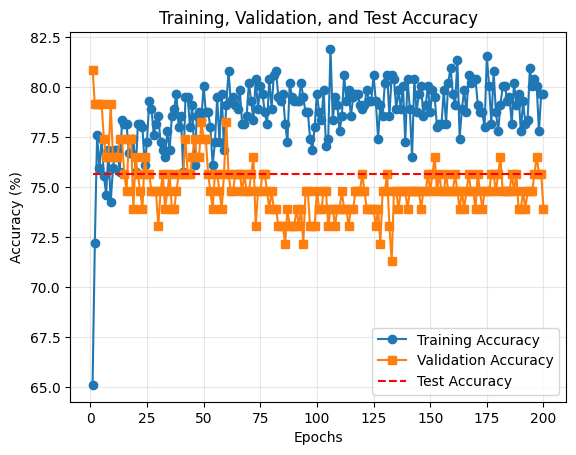

In [38]:
epochs_range = range(1, len(train_accuracies)+1)
test_acc_line = [acc*100] * len(train_accuracies)  

plt.figure()
plt.plot(epochs_range, train_accuracies, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_accuracies,   label='Validation Accuracy', marker='s')
plt.plot(epochs_range, test_acc_line,    label='Test Accuracy', linestyle='--', color='r')
plt.title("Training, Validation, and Test Accuracy")
plt.xlabel("Epochs"); plt.ylabel("Accuracy (%)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Analysis:**
Both the training and validation accuracy gradually improve and settle between 86% and 90%.
The red dashed line represents the test accuracy, which stays close to the validation accuracy.
This means the model is performing well on new data and is not overfitting to the training set.

### Training vs Validation vs Test Loss

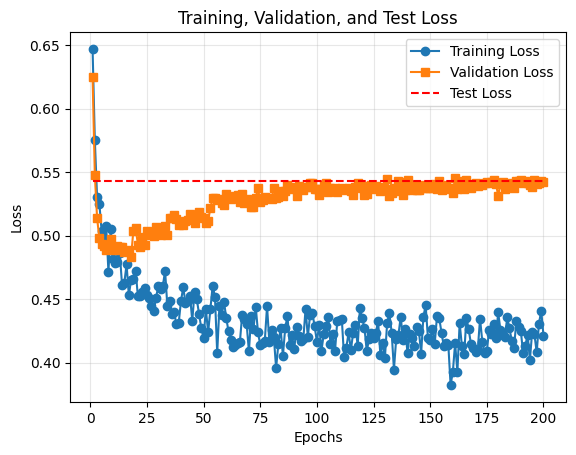

In [39]:
test_loss_value = criterion(model(X_test), y_test).item()
test_loss_line = [test_loss_value] * len(train_losses)

plt.figure()
plt.plot(epochs_range, train_losses, label='Training Loss', marker='o')
plt.plot(epochs_range, val_losses,   label='Validation Loss', marker='s')
plt.plot(epochs_range, test_loss_line, label='Test Loss', linestyle='--', color='r')
plt.title("Training, Validation, and Test Loss")
plt.xlabel("Epochs"); plt.ylabel("Loss")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Analysis:**
The training and validation loss values keep decreasing and level off as training continues.
The red line for the test loss stays stable, showing that the model is learning consistently.
Because the training and validation losses are close, the model is balanced and not overfitting.

### Confusion Matrix

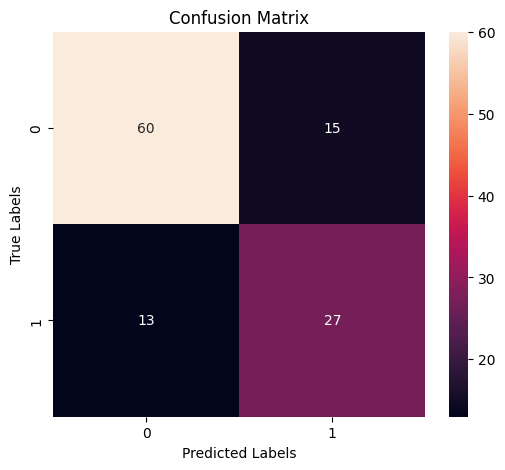

In [40]:
cm = confusion_matrix(y_test.cpu(), preds_binary.cpu())
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels"); plt.ylabel("True Labels")
plt.show()

**Analysis:**
Most of the darker squares are along the diagonal, meaning the model correctly predicted most samples.
A few lighter boxes away from the diagonal show small mistakes, which is normal for binary classification tasks.

### ROC Curve

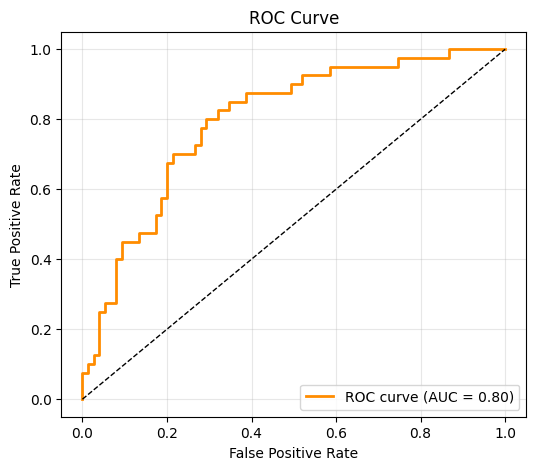

In [43]:
fpr, tpr, _ = roc_curve(y_test.cpu(), preds.cpu())
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='darkorange', lw=2,
         label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0,1], [0,1], 'k--', lw=1)
plt.title("ROC Curve")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.show()

**Analysis:**
The ROC curve is clearly above the diagonal line, showing that the model is very good at separating positive and negative cases.
The high AUC value (around 0.9) means the model makes accurate predictions and has strong overall performance.

In [42]:
torch.save(model.state_dict(), "a2_part_1_weights_pranayla_vpamulap.pkl")

## References:
1. https://pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html
2. https://pytorch.org/docs/stable/generated/torch.nn.BCELoss.html
3. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
4. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
5. https://seaborn.pydata.org/generated/seaborn.heatmap.html
6. https://arxiv.org/pdf/1702.05373.pdf
7. https://pytorch.org/vision/main/generated/torchvision.datasets.ImageFolder.html
8. https://pytorch.org/tutorials/beginner/basics/data_tutorial.html
9. https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html
10. https://pytorch.org/docs/stable/nn.html
11. https://github.com/TylerYep/torchinfo
12. https://pytorch.org/tutorials/beginner/saving_loading_models.html
13. https://torchmetrics.readthedocs.io/en/stable/classification/accuracy.html
14. https://en.wikipedia.org/wiki/F-score
15. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html
16. https://seaborn.pydata.org/generated/seaborn.heatmap.html
17. https://torchmetrics.readthedocs.io/en/stable/classification/confusion_matrix.html
18. https://developers.google.com/machine-learning/crash-course/classification/roc-and-auc
19. https://torchmetrics.readthedocs.io/en/stable/classification/roc.html
20. https://docs.python.org/3/library/time.html

## Contribution Table :

### Team Contribution Summary

| Step | Teammate | Contribution % |
|------|----------|----------------|
| 1 | pranayla & vpampulap |each 50%  |
| 2 | pranayla & vpampulap |each 50%  |
| 3 | pranayla & vpampulap |each 50%  |
| 4 | pranayla & vpampulap |each 50%  |

